# Inflation and the interest rate — ARDL with makystats

**Series.** Quarterly inflation `Dp` and interest rate `R` (`data/interest_inflation.csv`), 1972Q2–1998Q4.

**Model choice.** On this sample, information criteria prefer a **long lag on inflation** and **little dynamics in R**:

| Criterion | Preferred |
|-----------|-----------|
| **BIC** | `ARDL(4, 0)` — four lags of `Dp`, only contemporaneous `R` |
| **AIC** | `ARDL(4, 1)` — same, plus one lag of `R` |

We estimate **`ARDL(4, 0)`, case 3** as the main specification (BIC), then show the selection table.

**Why not ARDL(2, 2)?** A symmetric (2, 2) is a common *default* in tutorials, but here it is **dominated** on AIC/BIC (roughly −563 vs −746). Quarterly inflation needs the **year lag** (lag 4); extra lags of `R` add little once that is allowed.


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from makystats import ardl, select_ardl_order

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

## 2. Data


In [2]:
raw = pd.read_csv("data/interest_inflation.csv")
raw.index = pd.PeriodIndex.from_fields(
    year=raw["year"].astype(int), quarter=raw["quarter"].astype(int), freq="Q"
)
y = raw["Dp"].astype(float)
x = raw[["R"]].astype(float)
print(y.index[0], "→", y.index[-1], f"({len(y)} obs.)")


1972Q2 → 1998Q4 (107 obs.)


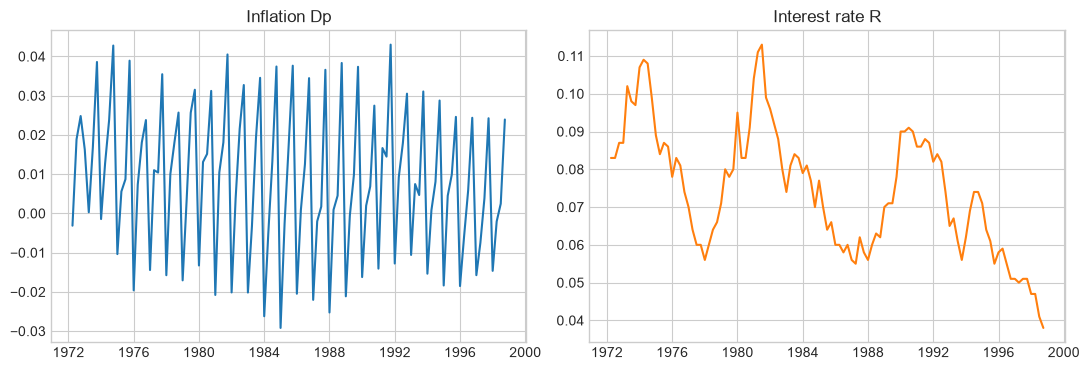

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(y.to_timestamp(), color="C0")
axes[0].set_title("Inflation Dp")
axes[1].plot(x["R"].to_timestamp(), color="C1")
axes[1].set_title("Interest rate R")
fig.tight_layout()
plt.show()


## 3. Order selection first

Search \(p \in \{0,\ldots,4\}\), \(q_R \in \{0,\ldots,3\}\), case 3. Rank by **BIC** (parsimony on a moderate quarterly sample).


In [4]:
table = select_ardl_order(
    y, x=x, maxlag=4, maxorder=3, case=3, ic="bic", verbose=False
)
print(table.head(8))
print("Best (BIC):", table.index[0])


            p     order         aic         bic        hqic          ll  \
ARDL(4; 0)  4  {'R': 0} -745.667119 -729.858745 -739.264186  378.833559   
ARDL(4; 1)  4  {'R': 1} -748.003689 -729.560586 -740.533601  381.001845   
ARDL(4; 2)  4  {'R': 2} -746.497962 -725.420130 -737.960718  381.248981   
ARDL(4; 3)  4  {'R': 3} -745.818558 -722.105997 -736.214159  381.909279   
ARDL(3; 1)  3  {'R': 1} -646.527565 -630.661219 -640.099642  329.263782   
ARDL(3; 2)  3  {'R': 2} -646.637469 -628.126733 -639.138226  330.318734   
ARDL(3; 3)  3  {'R': 3} -645.442890 -624.287763 -636.872327  330.721445   
ARDL(3; 0)  3  {'R': 0} -635.692548 -622.470593 -630.335945  322.846274   

            n_obs  case  q_R  q  
ARDL(4; 0)    103     3    0  0  
ARDL(4; 1)    103     3    1  1  
ARDL(4; 2)    103     3    2  2  
ARDL(4; 3)    103     3    3  3  
ARDL(3; 1)    104     3    1  1  
ARDL(3; 2)    104     3    2  2  
ARDL(3; 3)    104     3    3  3  
ARDL(3; 0)    104     3    0  0  
Best (BIC): ARDL(4

### Reading the table

- **ARDL(4; 0)** usually tops BIC: seasonal-style persistence in `Dp`, rate enters only in levels at \(t\).
- **ARDL(4; 1)** is close (and often best by AIC): one lag of `R` is optional.
- **ARDL(2; 2)** ranks much lower — do not keep it as the reported model on IC grounds.


## 4. Main estimate: ARDL(4, 0), case 3


In [6]:
res = ardl(y, x=x, lags=4, order=0, case=3).fit(verbose=False)
print(res.summary())

                              ARDL Model Results                              
Dep. Variable: Dp                                        No. Observations: 103
Model:         ARDL(4, 0)                            Log Likelihood:   378.834
Method:        OLS (conditional)                  S.D. of innov.:   0.00614537
Case (PSS):    3 (Constant)                         AIC:              -745.667
Date:          Tue, 27 Oct 2026                     BIC:              -729.859
Time:          16:57:58                             HQIC:             -739.264
            coef    std err          t      P>|t|     [0.025     0.975]
const    -0.0052     0.0030    -1.7481     0.0836    -0.0111     0.0007
Dp.L1    -0.1638     0.0556    -2.9466     0.0040    -0.2741    -0.0535
Dp.L2    -0.1591     0.0563    -2.8269     0.0057    -0.2708    -0.0474
Dp.L3    -0.1584     0.0566    -2.7964     0.0062    -0.2708    -0.0460
Dp.L4     0.8011     0.0556    14.4130     0.0000     0.6908     0.9115
R.L0      0.140

### Interpretation

- **Bounds F** is smaller than under the missized (2, 2), but still typically rejects “no levels relation” at 5% on Pesaran’s asymptotic table (check Narayan if you stress small-sample critical values).
- **Long-run coefficient on `R`**: long-run association between the rate and inflation (descriptive; not a structural policy multiplier by itself).
- **Four lags of `Dp`**: absorb the strong quarterly pattern that made lag 4 show up in pure ARMA work on the same series.


## 5. UECM (Conditional EC) and bounds test

`summary_uecm()` reports the **conditional error-correction** form (levels of \(y\) and \(x\) lagged, short-run differences) and the **long-run multipliers** \(\theta\).

`summary_bounds()` is the Pesaran / Narayan **F-bounds** test for a levels relationship.


In [8]:
print(res.summary_uecm())
print(res.summary_bounds())

                              UECM Model Results                              
Dep. Variable: D.Dp                                      No. Observations: 103
Model:         UECM(4, …)                            Log Likelihood:   378.834
Method:        OLS (reparam. ARDL)                  AIC:              -745.667
Case (PSS):    3 (Constant)                         BIC:              -729.859
              coef    std err          t      P>|t|     [0.025     0.975]
const      -0.0052     0.0030    -1.7481     0.0836    -0.0111     0.0007
Dp.L1      -0.6801     0.2002    -3.3981     0.0010    -1.0775    -0.2828
D.Dp.L1    -0.4836     0.1527    -3.1665     0.0021    -0.7868    -0.1805
D.Dp.L2    -0.6427     0.1043    -6.1597     0.0000    -0.8499    -0.4356
D.Dp.L3    -0.8011     0.0556   -14.4130     0.0000    -0.9115    -0.6908
R.L1        0.1409     0.0506     2.7819     0.0065     0.0403     0.2414
D.R.L0      0.1409     0.0506     2.7819     0.0065     0.0403     0.2414

Long run (mu

## 6. ECM and diagnostics


                            ECM (Error Correction)                            
              coef    std err          t      P>|t|
COINTEQ    -0.6801     0.2043    -3.3292     0.0012
D.R.L0      0.1409     0.1139     1.2370     0.2191
D.Dp.L1    -0.4836     0.1557    -3.1072     0.0025
D.Dp.L2    -0.6427     0.1068    -6.0192     0.0000
D.Dp.L3    -0.8011     0.0574   -13.9499     0.0000
const      -0.0052     0.0016    -3.3093     0.0013

Half-life (approx.): 0.608
α=-0.6801 (p=0.001232) : retour vers l'équilibre (α<0)
None


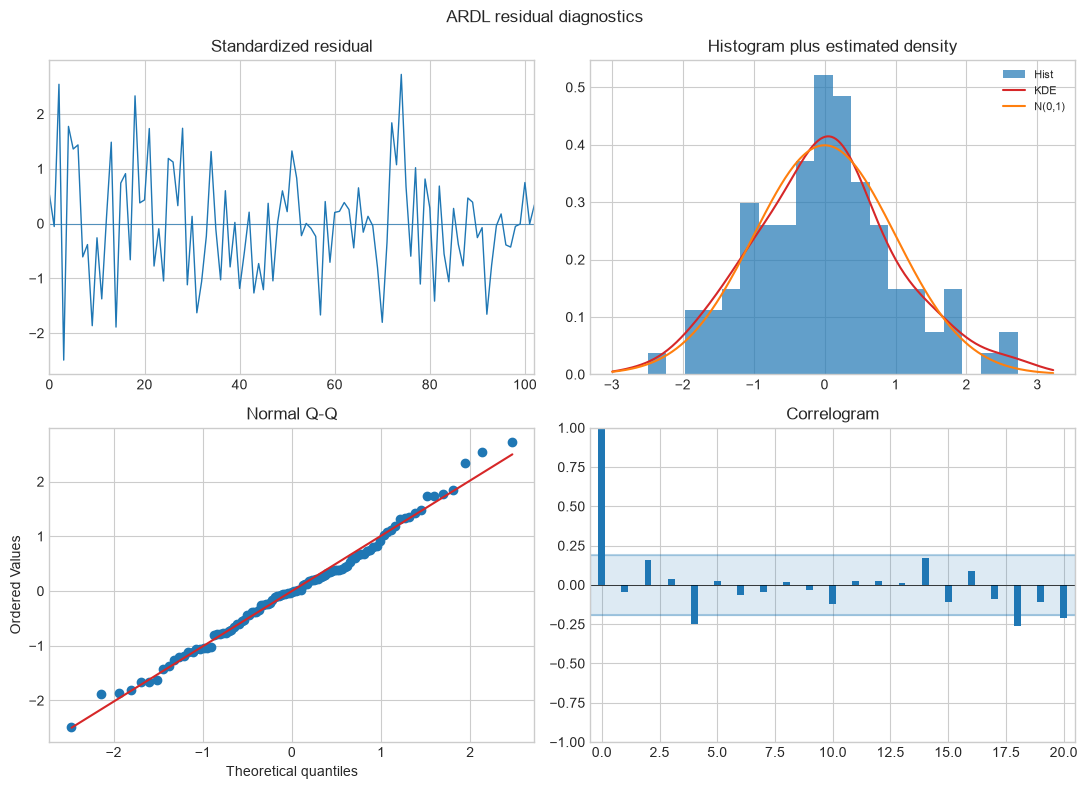

In [9]:
print(res.summary_ecm())
fig = res.plot_diagnostics()
plt.show()


## 7. Optional: AIC-preferred ARDL(4, 1)


In [10]:
res_aic = ardl(y, x=x, lags=4, order=1, case=3).fit(verbose=False)
print(res_aic.summary_uecm())
print(res_aic.summary_bounds())

                              UECM Model Results                              
Dep. Variable: D.Dp                                      No. Observations: 103
Model:         UECM(4, …)                            Log Likelihood:   381.002
Method:        OLS (reparam. ARDL)                  AIC:              -748.004
Case (PSS):    3 (Constant)                         BIC:              -729.561
              coef    std err          t      P>|t|     [0.025     0.975]
const      -0.0070     0.0031    -2.2997     0.0236    -0.0131    -0.0010
Dp.L1      -0.7804     0.2031    -3.8426     0.0002    -1.1835    -0.3773
D.Dp.L1    -0.4097     0.1547    -2.6489     0.0094    -0.7167    -0.1027
D.Dp.L2    -0.5891     0.1060    -5.5552     0.0000    -0.7996    -0.3786
D.Dp.L3    -0.7685     0.0570   -13.4799     0.0000    -0.8817    -0.6554
R.L1        0.1756     0.0527     3.3327     0.0012     0.0710     0.2802
D.R.L0     -0.0643     0.1126    -0.5712     0.5692    -0.2879     0.1592

Long run (mu

## Takeaways

1. **Select lags with IC** (or theory), then report bounds — not the reverse with a fixed (2, 2).
2. On this file, **BIC → ARDL(4, 0)**; **AIC → ARDL(4, 1)**.
3. A tutorial default ARDL(2, 2) can **inflate** residual seasonality and produce a very large F that is not IC-optimal.
4. Same data as the Inflation **ARMA** example: ARDL adds the rate and a formal levels test.
